# Notebook 11 – EDA Visualization

Every chart follows: **Why selected → Generate → Interpret → Insight**. No chart is created just for the sake of it.

**Sprint 4 – Data Inspection & Exploratory Data Analysis**  
Workflow: `Load → Inspect → Understand → Analyze → Visualize → Identify Problems → Document Findings`  
**Dataset:** Telco Customer Churn (IBM sample data, 7,043 customers × 21 columns)

In [1]:
import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="deep")
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 140)

# Load the RAW dataset (nothing has been modified yet)
PATH = "../data/telco.csv"
if not os.path.exists(PATH):   # fallback: download straight from the public source
    PATH = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"
df_raw = pd.read_csv(PATH)
df = df_raw.copy()
print("Loaded:", df.shape)

# NOTE: 'TotalCharges' is stored as text in the raw file (11 blank strings, see 03_Data_Quality).
# For ANALYSIS ONLY we create a numeric working copy; blanks become NaN. The raw file is untouched,
# and the formal treatment of these rows is deferred to the preprocessing sprint.
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")

num_cols = ["tenure", "MonthlyCharges", "TotalCharges"]
cat_cols = [c for c in df.columns if c not in num_cols + ["customerID"]]
target = "Churn"
df["ChurnFlag"] = (df["Churn"] == "Yes").astype(int)   # helper for rates/correlations (analysis only)

Loaded: (7043, 21)


In [2]:
df["tenure_group"] = pd.cut(df["tenure"], bins=[-1, 12, 24, 48, 72], labels=["0-12", "13-24", "25-48", "49-72"])

### Topic Explanation

A histogram groups numeric values into bins to show distribution shape, concentration, gaps, and possible skew.

## 1. Histogram – tenure

**Why this visualization?** A histogram is the right tool to see the *shape* of one continuous/discrete numeric variable (spikes, gaps, skew).

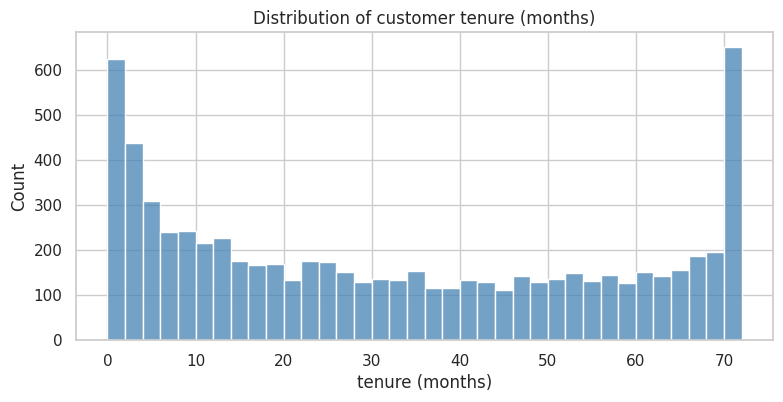

In [3]:
plt.figure(figsize=(9, 4)); sns.histplot(df["tenure"], bins=36, color="steelblue")
plt.title("Distribution of customer tenure (months)"); plt.xlabel("tenure (months)"); plt.show()

**Interpretation:** Two tall bars at the extremes (1 month and 72 months) and a fairly even middle.

**Insight:** The base is polarised into brand-new customers and long-term loyal ones; there is no 'typical' customer age, so the mean (32) is not representative.

### Topic Explanation

A box plot compares medians and spread using quartiles and can highlight potential outliers across groups.

## 2. Box Plot – MonthlyCharges by Churn

**Why this visualization?** A box plot compares the median, spread and outliers of a numeric variable across groups.

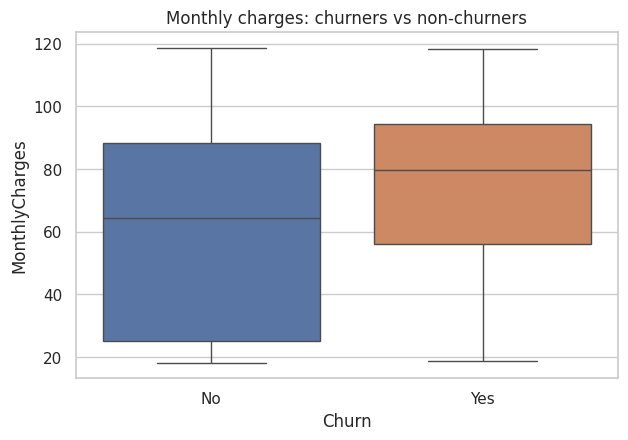

In [4]:
plt.figure(figsize=(7, 4.5)); sns.boxplot(data=df, x="Churn", y="MonthlyCharges", palette=["#4c72b0", "#dd8452"])
plt.title("Monthly charges: churners vs non-churners"); plt.show()

**Interpretation:** The churned group's box sits higher (median ≈ \$80 vs ≈ \$64) with a narrower lower tail – few churners pay under \$40.

**Insight:** Churn is concentrated among higher-paying (mostly fibre/bundle) customers; price sensitivity is a plausible driver.

### Topic Explanation

Bar and count plots compare category frequencies or rates; rates are useful when group sizes differ.

## 3. Bar Chart – Churn rate by Contract

**Why this visualization?** A bar chart of *rates* (not raw counts) compares a target proportion across categories fairly.

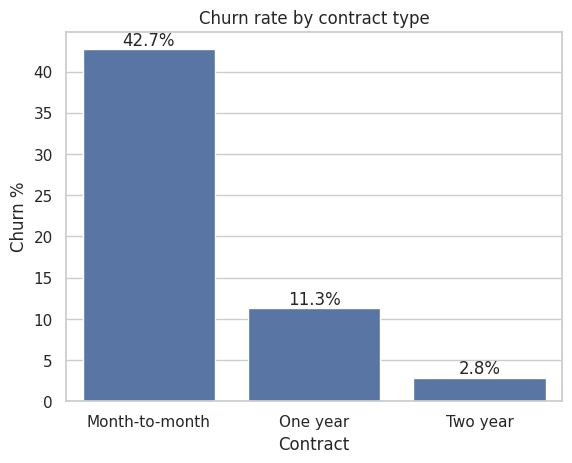

In [5]:
rate = df.groupby("Contract")["ChurnFlag"].mean().mul(100).sort_values(ascending=False)
ax = sns.barplot(x=rate.index, y=rate.values); ax.set_ylabel("Churn %"); ax.set_title("Churn rate by contract type")
for i, v in enumerate(rate.values): ax.text(i, v + .5, f"{v:.1f}%", ha="center")
plt.show()

**Interpretation:** Month-to-month ≈ 42.7%, one-year ≈ 11.3%, two-year ≈ 2.8%.

**Insight:** Contract length is the single most powerful retention lever: committed customers almost never leave. A migration offer from month-to-month to annual plans targets the largest at-risk group.

### Topic Explanation

Bar and count plots compare category frequencies or rates; rates are useful when group sizes differ.

## 4. Count Plot – InternetService split by Churn

**Why this visualization?** A count plot with `hue` shows both the *size* of each group and the churn composition within it.

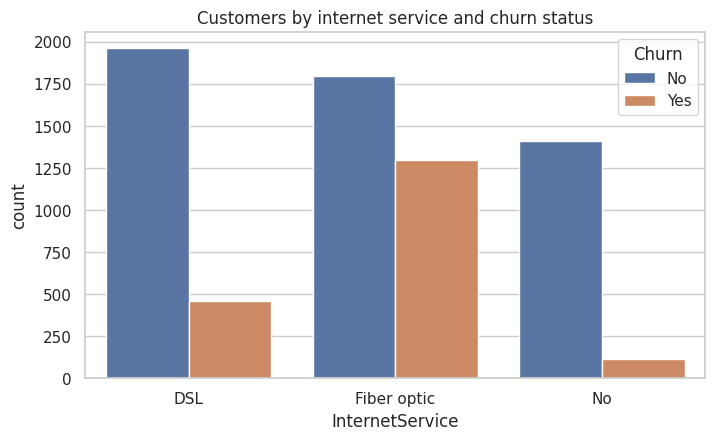

In [6]:
plt.figure(figsize=(8, 4.5)); sns.countplot(data=df, x="InternetService", hue="Churn", palette=["#4c72b0", "#dd8452"])
plt.title("Customers by internet service and churn status"); plt.show()

**Interpretation:** Fibre optic is the largest group and has the largest churned bar, even though DSL has almost as many customers; 'No' has almost no churn.

**Insight:** Fibre has high volume *and* high churn (≈ 42%), so it is where most of the lost customers come from; investigate fibre pricing/quality.

### Topic Explanation

A scatter plot displays paired numeric values to reveal association, clusters, and unusual observations.

## 5. Scatter Plot – tenure vs MonthlyCharges coloured by Churn

**Why this visualization?** A scatter plot reveals the relationship (and clusters) between two numeric variables; colour adds the target as a third dimension.

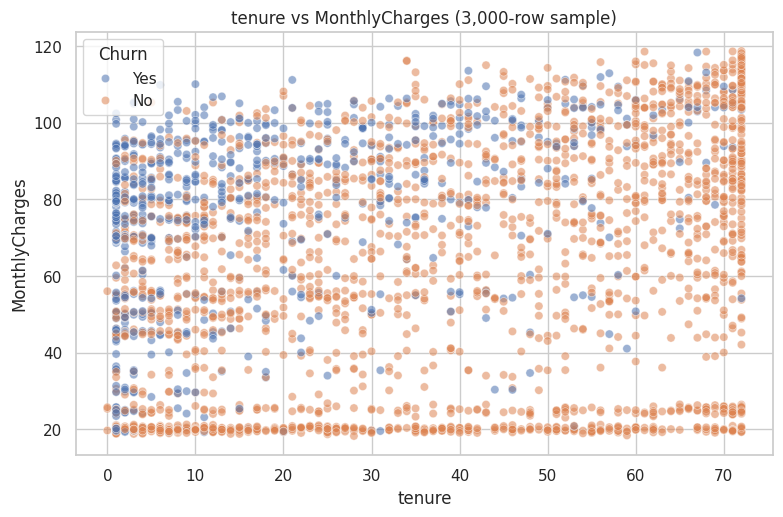

In [7]:
plt.figure(figsize=(9, 5.5)); sns.scatterplot(data=df.sample(3000, random_state=3), x="tenure", y="MonthlyCharges", hue="Churn", alpha=.55, palette=["#4c72b0", "#dd8452"])
plt.title("tenure vs MonthlyCharges (3,000-row sample)"); plt.show()

**Interpretation:** Orange churners crowd the upper-left (short tenure, high bill). Long-tenure customers are mostly blue regardless of price.

**Insight:** The highest-risk zone is *new customers on expensive plans*; the first months are a critical retention window.

### Topic Explanation

A line plot shows how a measure changes across an ordered sequence or continuous axis.

## 6. Line Plot – Churn rate and average bill along tenure

**Why this visualization?** A line plot is the natural way to show how a measure changes along an ordered variable (here months of tenure).

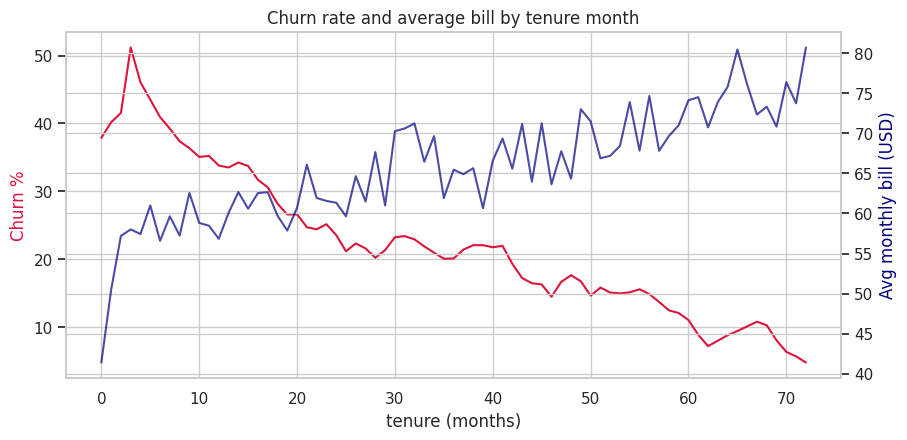

In [8]:
by_t = df.groupby("tenure").agg(churn=("ChurnFlag", "mean"), avg_bill=("MonthlyCharges", "mean"), n=("ChurnFlag", "size"))
by_t["churn"] *= 100
by_t["churn_smooth"] = by_t["churn"].rolling(5, center=True, min_periods=1).mean()
fig, ax1 = plt.subplots(figsize=(10, 4.5))
ax1.plot(by_t.index, by_t["churn_smooth"], color="crimson", label="churn % (5-month rolling mean)"); ax1.set_ylabel("Churn %", color="crimson"); ax1.set_xlabel("tenure (months)")
ax2 = ax1.twinx(); ax2.plot(by_t.index, by_t["avg_bill"], color="navy", alpha=.7, label="average monthly bill"); ax2.set_ylabel("Avg monthly bill (USD)", color="navy")
plt.title("Churn rate and average bill by tenure month"); plt.show()

**Interpretation:** Churn is highest in the first months (≈ 60% at month 1) and decays steadily toward ≈ 10% or below after about 5 years; the average bill drifts upward with tenure.

**Insight:** Risk falls rapidly with every month a customer stays – the first 3–12 months deserve the strongest retention effort.

### Topic Explanation

A violin plot combines group comparison with a density shape to show where values are concentrated.

## 7. Violin Plot – tenure by Contract

**Why this visualization?** A violin plot shows the full distribution shape (including multi-modality) for each group – more informative than a box plot when shapes differ.

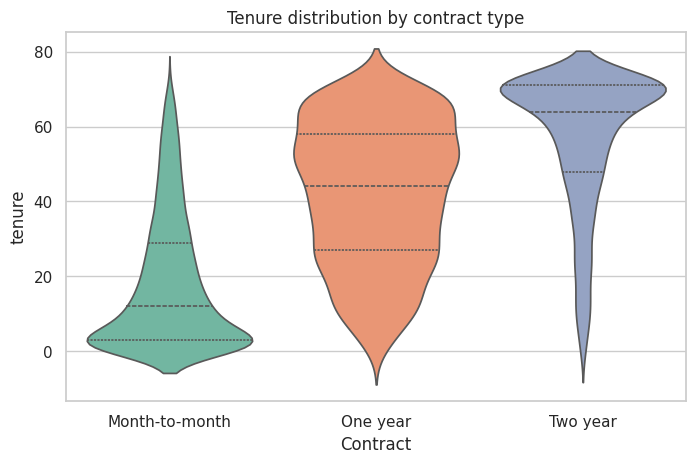

In [9]:
plt.figure(figsize=(8, 4.8)); sns.violinplot(data=df, x="Contract", y="tenure", inner="quartile", palette="Set2")
plt.title("Tenure distribution by contract type"); plt.show()

**Interpretation:** Month-to-month is concentrated at short tenures; one-year spreads widely; two-year concentrates at long tenures with a mass at the 72-month cap.

**Insight:** Contract type and tenure are strongly linked: committed customers are those who have stayed longest (or stayed because they were committed).

### Topic Explanation

This topic distinguishes input features used for analysis from the target variable the analysis may aim to explain or predict.

## 8. Pair Plot – numeric features by Churn

**Why this visualization?** A pair plot summarises all pairwise numeric relationships and the class-wise distributions in one view.

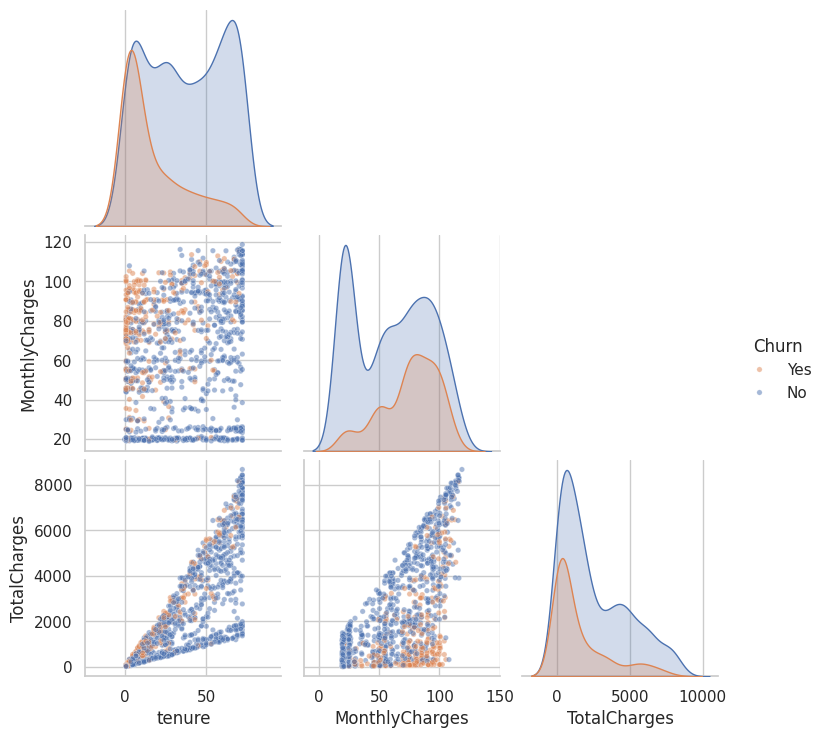

In [10]:
g = sns.pairplot(df.sample(1200, random_state=7), vars=["tenure", "MonthlyCharges", "TotalCharges"], hue="Churn", corner=True,
                 palette={"No": "#4c72b0", "Yes": "#dd8452"}, plot_kws={"alpha": .5, "s": 15})
plt.show()

**Interpretation:** Strong tenure–TotalCharges fan, two clusters in MonthlyCharges, and churners shifted to low tenure on all panels.

**Insight:** Numeric features overlap between classes; no single threshold separates churners, so a multivariate model is justified.

### Topic Explanation

A correlation heatmap uses colour to summarise pairwise correlation strengths and directions.

## 9. Heatmap – correlation matrix

**Why this visualization?** A heatmap displays many pairwise numbers at once and highlights redundancy and target relationships through colour.

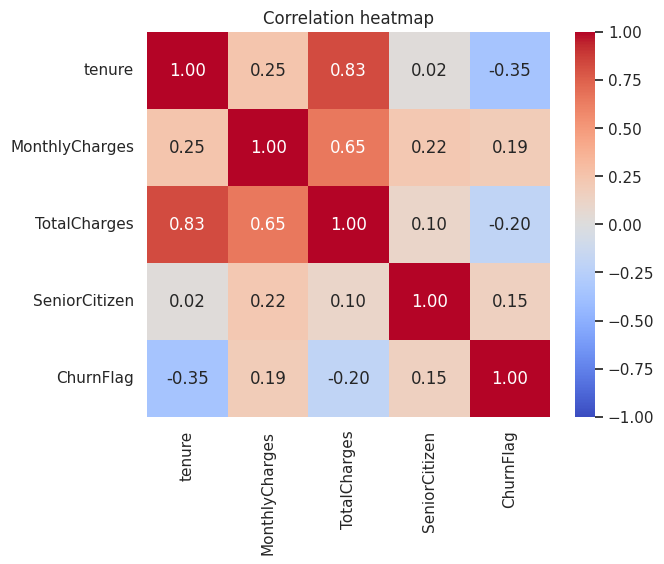

In [11]:
corr = df[["tenure", "MonthlyCharges", "TotalCharges", "SeniorCitizen", "ChurnFlag"]].corr()
plt.figure(figsize=(6.5, 5)); sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1)
plt.title("Correlation heatmap"); plt.show()

**Interpretation:** tenure–TotalCharges 0.83 (red); tenure–Churn –0.35 (blue); MonthlyCharges–Churn +0.19.

**Insight:** `TotalCharges` is redundant with tenure×price; tenure is the strongest numeric predictor of churn.

### Topic Explanation

This topic describes the shape of values, including symmetry, skewness, centre, spread, and tail behaviour.

## 10. Distribution Plot – tenure and MonthlyCharges by Churn

**Why this visualization?** Overlayed density curves (`kdeplot`/`displot`) compare distributions of a numeric variable between the target classes directly.

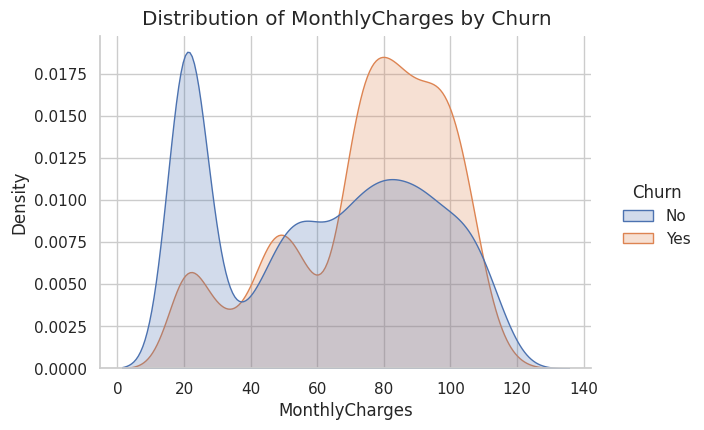

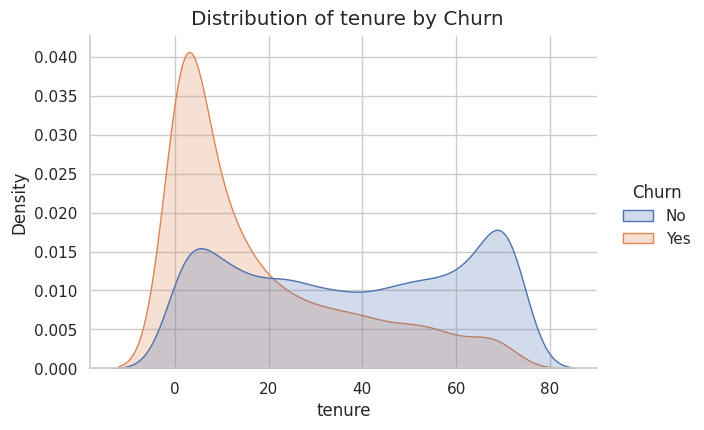

In [12]:
g = sns.displot(data=df, x="MonthlyCharges", hue="Churn", kind="kde", fill=True, common_norm=False, height=4.2, aspect=1.5, palette=["#4c72b0", "#dd8452"])
g.fig.suptitle("Distribution of MonthlyCharges by Churn", y=1.02); plt.show()
g = sns.displot(data=df, x="tenure", hue="Churn", kind="kde", fill=True, common_norm=False, height=4.2, aspect=1.5, palette=["#4c72b0", "#dd8452"])
g.fig.suptitle("Distribution of tenure by Churn", y=1.02); plt.show()

**Interpretation:** Non-churners have a large low-price peak (~\$20) that churners lack; churners' tenure density peaks near zero.

**Insight:** Customers on cheap phone-only plans rarely churn; churn is a problem of internet-bundle customers in their early months.

### Topic Explanation

This topic consolidates the notebook's findings into a concise summary for review and communication.

## Visualization Summary

| Chart | Question answered | Key insight |
|---|---|---|
| Histogram | Shape of tenure | Polarised: new vs loyal |
| Box plot | Bills by churn | Churners pay more |
| Bar chart | Churn by contract | Month-to-month ≈ 43% vs two-year ≈ 3% |
| Count plot | Internet service × churn | Fibre has the largest loss |
| Scatter | tenure vs bill | New + expensive = highest risk |
| Line plot | Churn along tenure | Risk decays with time |
| Violin | tenure by contract | Contracts and tenure are linked |
| Pair plot | All numeric pairs | No single feature separates classes |
| Heatmap | Correlations | TotalCharges redundant |
| Distribution plot | Class-wise densities | Low-price customers rarely churn |